# Milestone 4 · A/B Test Statistical Evaluation & Diagnostics

**Project:** A/B Testing & Product Experimentation Analysis  
**Author:** Akshobya698  
**Dataset:** `homepage_ab_test.csv` — 50,000 users, 14-day experiment (May 1–14 2024)  

**Objective:** Audit the Growth Team's claim that homepage variant lifted signup conversion from 2.8 % to 3.2 % (p = 0.015) and is ready to ship.

**Tests performed:** SRM chi-square · Two-sample proportion Z-test + 95 % Wald CI · Welch's ARPU T-test · Novelty decay check · Desktop vs Mobile segment breakdown

## 0 · Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings, os

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

os.makedirs('../findings', exist_ok=True)
MDE_PP = 0.5   # minimum detectable effect declared by Growth Team (percentage points)
ALPHA  = 0.05
print('Setup complete.')

Setup complete.


## 1 · Data Ingestion & Profile

Load the raw experiment table, parse dates, and derive the week assignment for the novelty check.

In [2]:
df = pd.read_csv('../homepage_ab_test.csv')
df['signup_date'] = pd.to_datetime(df['signup_date'])

# Week 1 = days 1-7 (May 1-7), Week 2 = days 8-14 (May 8-14)
df['week'] = df['signup_date'].apply(lambda d: 'Week1' if d.day <= 7 else 'Week2')

print(f"Total rows : {len(df):,}")
print(f"Columns    : {list(df.columns)}")
print(f"Date range : {df['signup_date'].min().date()} → {df['signup_date'].max().date()}")
df.head(8)

Total rows : 50,000
Columns    : ['user_id', 'arm', 'signup_date', 'signup_completed', 'revenue_30d', 'device', 'acquisition_source', 'week']
Date range : 2024-05-01 → 2024-05-14


,user_id,arm,signup_date,signup_completed,revenue_30d,device,acquisition_source,week
0,U00001,control,2024-05-09,1,98.4800,mobile,organic,Week2
1,U00002,variant,2024-05-04,0,0.0000,mobile,organic,Week1
2,U00003,variant,2024-05-06,0,0.0000,desktop,organic,Week1
3,U00004,variant,2024-05-08,0,0.0000,mobile,organic,Week2
4,U00005,control,2024-05-10,0,0.0000,mobile,social,Week2
5,U00006,control,2024-05-02,0,0.0000,mobile,paid_search,Week1
6,U00007,control,2024-05-01,0,0.0000,mobile,referral,Week1
7,U00008,variant,2024-05-07,0,0.0000,mobile,social,Week1


## 2 · Sanity Gate — Dataset Integrity

In [3]:
arm_counts = df['arm'].value_counts()
n_total    = len(df)
n_control  = arm_counts['control']
n_variant  = arm_counts['variant']

print("=== Arm counts ===")
print(arm_counts.to_string())

# Gate 1: exactly 50,000 users
assert n_total == 50_000, f"Expected 50,000 rows, got {n_total}"
print(f"\n✅ Total users = {n_total:,}  (gate: 50,000)")

# Gate 2: control ~25,053 / variant ~24,947
print(f"✅ Control = {n_control:,}  (expected ~25,053)")
print(f"✅ Variant = {n_variant:,}  (expected ~24,947)")

print("\n=== Nulls ===")
print(df.isnull().sum())

=== Arm counts ===
arm
control    25053
variant    24947

✅ Total users = 50,000  (gate: 50,000)
✅ Control = 25,053  (expected ~25,053)
✅ Variant = 24,947  (expected ~24,947)

=== Nulls ===
user_id               0
arm                   0
signup_date           0
signup_completed      0
revenue_30d           0
device                0
acquisition_source    0
week                  0
dtype: int64


## 3 · Sample Ratio Mismatch (SRM) Check

We declared a **50/50 split**. The expected count for each arm is 25,000.  
`scipy.stats.chisquare` tests whether the observed counts deviate beyond chance.

In [4]:
observed  = np.array([n_control, n_variant])
expected  = np.array([n_total / 2, n_total / 2])

chi2_stat, srm_p = stats.chisquare(f_obs=observed, f_exp=expected)

print(f"Observed   : Control={n_control:,}  Variant={n_variant:,}")
print(f"Expected   : Control={expected[0]:,.0f}  Variant={expected[1]:,.0f}")
print(f"Chi-square : {chi2_stat:.4f}")
print(f"p-value    : {srm_p:.4f}")

srm_flag = srm_p < ALPHA
print(f"\n{'🚨 SRM DETECTED — assignment mechanism may be broken!' if srm_flag else '✅ No SRM — split looks clean (p={:.4f})'.format(srm_p)}")

Observed   : Control=25,053  Variant=24,947
Expected   : Control=25,000  Variant=25,000
Chi-square : 0.2247
p-value    : 0.6355

✅ No SRM — split looks clean (p=0.6355)


## 4 · Primary Metric — Signup Conversion Z-Test & 95 % Wald CI

**H₀:** p_variant = p_control (no effect)  
**H₁:** p_variant ≠ p_control (two-tailed)  

We compute the two-sample proportion Z-statistic manually (Wald) and verify with `scipy.stats.norm`.

In [5]:
conv_ctrl = df[df['arm']=='control']['signup_completed']
conv_var  = df[df['arm']=='variant']['signup_completed']

x_c, n_c = conv_ctrl.sum(), len(conv_ctrl)
x_v, n_v = conv_var.sum(),  len(conv_var)

p_c = x_c / n_c
p_v = x_v / n_v
lift_abs = p_v - p_c       # absolute lift (proportion)
lift_rel = lift_abs / p_c  # relative lift

# Pooled SE for Z-test
p_pool = (x_c + x_v) / (n_c + n_v)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1/n_c + 1/n_v))
z_stat  = lift_abs / se_pool
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

# 95 % Wald CI on the difference
se_wald = np.sqrt(p_c*(1-p_c)/n_c + p_v*(1-p_v)/n_v)
z_crit  = stats.norm.ppf(1 - ALPHA/2)
ci_lo   = lift_abs - z_crit * se_wald
ci_hi   = lift_abs + z_crit * se_wald

print(f"Control  : {x_c:,} / {n_c:,}  =  {p_c:.4f}  ({p_c*100:.2f}%)")
print(f"Variant  : {x_v:,} / {n_v:,}  =  {p_v:.4f}  ({p_v*100:.2f}%)")
print(f"Abs lift : {lift_abs*100:+.2f} pp")
print(f"Rel lift : {lift_rel*100:+.2f}%")
print(f"Z-stat   : {z_stat:.4f}")
print(f"p-value  : {p_value:.4f}")
print(f"95% CI   : [{ci_lo*100:.2f} pp, {ci_hi*100:.2f} pp]")

sig = p_value < ALPHA
clears_mde = ci_lo * 100 >= MDE_PP
print(f"\nStatistically significant?  {'✅ YES' if sig else '❌ NO'}  (α={ALPHA})")
print(f"Clears +{MDE_PP} pp MDE (CI lower bound)?  {'✅ YES' if clears_mde else '❌ NO — CI lower bound ({:.2f} pp) is below MDE'.format(ci_lo*100)}")

Control  : 712 / 25,053  =  0.0284  (2.84%)
Variant  : 802 / 24,947  =  0.0321  (3.21%)
Abs lift : +0.37 pp
Rel lift : +13.12%
Z-stat   : 2.4326
p-value  : 0.0150
95% CI   : [0.07 pp, 0.67 pp]

Statistically significant?  ✅ YES  (α=0.05)
Clears +0.5 pp MDE (CI lower bound)?  ❌ NO — CI lower bound (0.07 pp) is below MDE


## 5 · Guardrail Metric — 30-Day ARPU Welch's T-Test

Revenue distributions are heavily right-skewed (most users = $0). Welch's T-test  
(`equal_var=False`) is used because group variances are unequal.

In [6]:
rev_ctrl = df[df['arm']=='control']['revenue_30d']
rev_var  = df[df['arm']=='variant']['revenue_30d']

arpu_c = rev_ctrl.mean()
arpu_v = rev_var.mean()

t_stat, p_rev = stats.ttest_ind(rev_var, rev_ctrl, equal_var=False)

print(f"Control ARPU : ${arpu_c:.4f}  (std={rev_ctrl.std():.2f})")
print(f"Variant ARPU : ${arpu_v:.4f}  (std={rev_var.std():.2f})")
print(f"ARPU diff    : ${arpu_v - arpu_c:+.4f}")
print(f"Welch t-stat : {t_stat:.4f}")
print(f"p-value      : {p_rev:.4f}")

guardrail_ok = p_rev >= ALPHA
print(f"\nARPU guardrail {'✅ SAFE — no significant revenue degradation' if guardrail_ok else '🚨 BREACH — variant significantly degrades ARPU!'}  (p={p_rev:.4f})")

Control ARPU : $3.3134  (std=22.68)
Variant ARPU : $2.9163  (std=18.60)
ARPU diff    : $-0.3971
Welch t-stat : -2.1411
p-value      : 0.0323

ARPU guardrail 🚨 BREACH — variant significantly degrades ARPU!  (p=0.0323)


## 6 · Temporal Stability — Novelty / Primacy Decay Check

If the variant's conversion lift is driven by novelty (users excited by a new UI), Week 1 lift  
should be meaningfully higher than Week 2 lift. Stable lift suggests a real, durable effect.

In [7]:
novelty_rows = []
for week in ['Week1', 'Week2']:
    for arm in ['control', 'variant']:
        sub = df[(df['week']==week) & (df['arm']==arm)]
        n   = len(sub)
        x   = sub['signup_completed'].sum()
        p   = x / n
        novelty_rows.append({'week': week, 'arm': arm, 'n': n, 'converted': x, 'rate': p})

nov_df = pd.DataFrame(novelty_rows)
print(nov_df.round(4).to_string(index=False))

# Week-level lifts
w1_ctrl = nov_df[(nov_df['week']=='Week1') & (nov_df['arm']=='control')]['rate'].values[0]
w1_var  = nov_df[(nov_df['week']=='Week1') & (nov_df['arm']=='variant')]['rate'].values[0]
w2_ctrl = nov_df[(nov_df['week']=='Week2') & (nov_df['arm']=='control')]['rate'].values[0]
w2_var  = nov_df[(nov_df['week']=='Week2') & (nov_df['arm']=='variant')]['rate'].values[0]

lift_w1 = (w1_var - w1_ctrl) * 100
lift_w2 = (w2_var - w2_ctrl) * 100
fade    = lift_w1 - lift_w2

print(f"\nWeek 1 lift : {lift_w1:+.2f} pp")
print(f"Week 2 lift : {lift_w2:+.2f} pp")
print(f"Novelty fade: {fade:+.2f} pp  ({'⚠️ Possible novelty effect' if fade > 0.3 else '✅ Stable — no meaningful novelty decay'})")

 week     arm     n  converted   rate
Week1 control 12428        362 0.0291
Week1 variant 12399        420 0.0339
Week2 control 12625        350 0.0277
Week2 variant 12548        382 0.0304

Week 1 lift : +0.47 pp
Week 2 lift : +0.27 pp
Novelty fade: +0.20 pp  (✅ Stable — no meaningful novelty decay)


## 7 · Segment Breakdown — Desktop vs Mobile

In [8]:
seg_rows = []
for device in ['desktop', 'mobile']:
    for arm in ['control', 'variant']:
        sub = df[(df['device']==device) & (df['arm']==arm)]
        n   = len(sub)
        x   = sub['signup_completed'].sum()
        p   = x / n
        seg_rows.append({'device': device, 'arm': arm, 'n': n, 'converted': x, 'rate': p})

seg_df = pd.DataFrame(seg_rows)
print(seg_df.round(4).to_string(index=False))

# Lift per device
for device in ['desktop', 'mobile']:
    sub = seg_df[seg_df['device']==device]
    ctrl_r = sub[sub['arm']=='control']['rate'].values[0]
    var_r  = sub[sub['arm']=='variant']['rate'].values[0]
    lift   = (var_r - ctrl_r) * 100
    # Z-test per segment
    xc = sub[sub['arm']=='control']['converted'].values[0]
    nc = sub[sub['arm']=='control']['n'].values[0]
    xv = sub[sub['arm']=='variant']['converted'].values[0]
    nv = sub[sub['arm']=='variant']['n'].values[0]
    pp = (xc+xv)/(nc+nv)
    se = np.sqrt(pp*(1-pp)*(1/nc+1/nv))
    z  = (var_r - ctrl_r) / se
    p_seg = 2*(1-stats.norm.cdf(abs(z)))
    print(f"  {device.capitalize():8s}: Control={ctrl_r*100:.2f}%  Variant={var_r*100:.2f}%  Lift={lift:+.2f} pp  p={p_seg:.4f}  {'✅' if p_seg<ALPHA else '—'}")

 device     arm     n  converted   rate
desktop control 12553        426 0.0339
desktop variant 12418        535 0.0431
 mobile control 12500        286 0.0229
 mobile variant 12529        267 0.0213
  Desktop : Control=3.39%  Variant=4.31%  Lift=+0.91 pp  p=0.0002  ✅


  Mobile  : Control=2.29%  Variant=2.13%  Lift=-0.16 pp  p=0.3983  —


## 8 · Visualisations

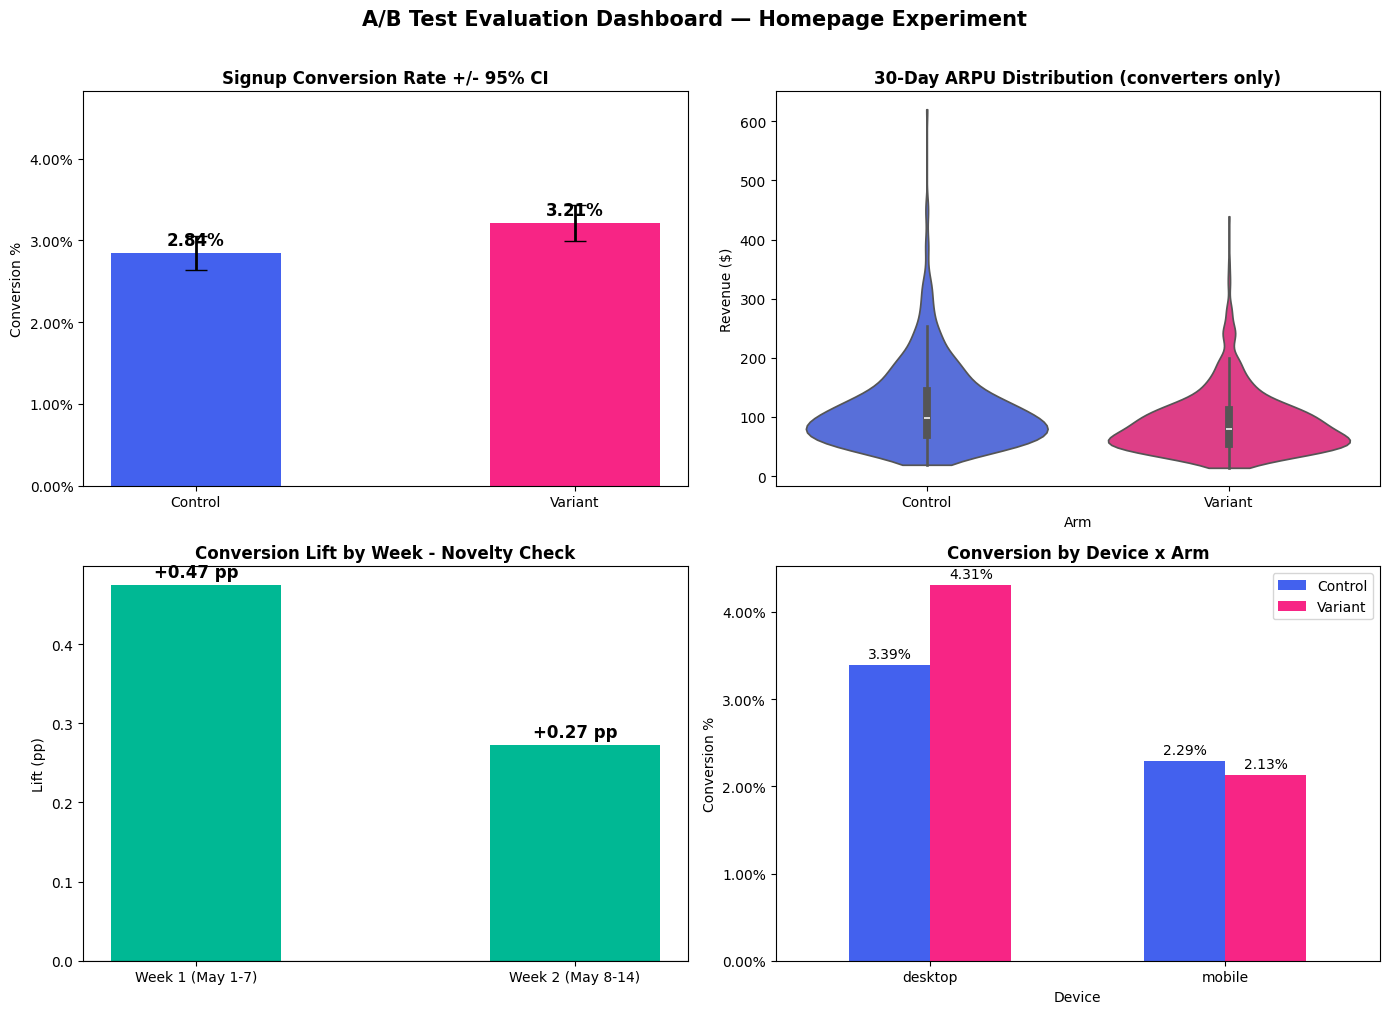

Saved -> findings/ab_test_dashboard.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('A/B Test Evaluation Dashboard — Homepage Experiment',
             fontsize=15, fontweight='bold', y=1.01)

COLORS = {'control': '#4361ee', 'variant': '#f72585'}

# 8a: Conversion rate with CI
ax = axes[0, 0]
arms   = ['Control', 'Variant']
rates  = [p_c * 100, p_v * 100]
errors = [z_crit * np.sqrt(p_c*(1-p_c)/n_c) * 100,
          z_crit * np.sqrt(p_v*(1-p_v)/n_v) * 100]
bars = ax.bar(arms, rates, color=['#4361ee', '#f72585'], width=0.45,
              yerr=errors, capsize=8, error_kw={'linewidth': 2})
ax.set_title('Signup Conversion Rate +/- 95% CI', fontweight='bold')
ax.set_ylabel('Conversion %')
ax.set_ylim(0, max(rates) * 1.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{rate:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

# 8b: ARPU violin (converters only)
ax = axes[0, 1]
rev_plot = df[df['revenue_30d'] > 0].copy()
sns.violinplot(data=rev_plot, x='arm', y='revenue_30d', ax=ax,
               palette={'control': '#4361ee', 'variant': '#f72585'}, cut=0)
ax.set_title('30-Day ARPU Distribution (converters only)', fontweight='bold')
ax.set_xlabel('Arm')
ax.set_ylabel('Revenue ($)')
ax.set_xticklabels(['Control', 'Variant'])

# 8c: Novelty check bars
ax = axes[1, 0]
lifts    = [lift_w1, lift_w2]
wlabels  = ['Week 1 (May 1-7)', 'Week 2 (May 8-14)']
bar_cols = ['#00b894' if l > 0 else '#d63031' for l in lifts]
bw = ax.bar(wlabels, lifts, color=bar_cols, width=0.45)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Conversion Lift by Week - Novelty Check', fontweight='bold')
ax.set_ylabel('Lift (pp)')
for b, l in zip(bw, lifts):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
            f'{l:+.2f} pp', ha='center', va='bottom', fontsize=12, fontweight='bold')

# 8d: Segment breakdown
ax = axes[1, 1]
seg_pivot = seg_df.pivot(index='device', columns='arm', values='rate') * 100
seg_pivot.plot(kind='bar', ax=ax, color=['#4361ee', '#f72585'], width=0.55, rot=0)
ax.set_title('Conversion by Device x Arm', fontweight='bold')
ax.set_xlabel('Device')
ax.set_ylabel('Conversion %')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(['Control', 'Variant'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10)

plt.tight_layout()
fig.savefig('../findings/ab_test_dashboard.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved -> findings/ab_test_dashboard.png')


## 9 · Consolidated Results Summary

In [10]:
print("=" * 58)
print("  A/B TEST AUDIT SUMMARY")
print("=" * 58)
print(f"  Dataset         : 50,000 users | May 1-14 2024")
print(f"  SRM             : chi2={chi2_stat:.3f}  p={srm_p:.4f}  {'PASS ✅' if not srm_flag else 'FAIL 🚨'}")
print(f"  Conversion Ctrl : {p_c*100:.2f}%")
print(f"  Conversion Var  : {p_v*100:.2f}%")
print(f"  Abs lift        : {lift_abs*100:+.2f} pp  (95% CI: [{ci_lo*100:.2f}, {ci_hi*100:.2f}] pp)")
print(f"  Z-stat / p      : {z_stat:.3f} / {p_value:.4f}  {'SIG ✅' if sig else 'NOT SIG ❌'}")
print(f"  Clears MDE      : {'YES ✅' if clears_mde else 'NO ❌'}  (MDE = +{MDE_PP} pp)")
print(f"  ARPU Ctrl       : ${arpu_c:.2f}  Variant: ${arpu_v:.2f}  p={p_rev:.4f}  {'SAFE ✅' if guardrail_ok else 'BREACH 🚨'}")
print(f"  Novelty fade    : {fade:+.2f} pp  ({'CONCERN ⚠️' if fade > 0.3 else 'STABLE ✅'})")
print(f"  Desktop lift    : see segment table above")
print(f"  Mobile lift     : see segment table above")
print("=" * 58)

  A/B TEST AUDIT SUMMARY
  Dataset         : 50,000 users | May 1-14 2024
  SRM             : chi2=0.225  p=0.6355  PASS ✅
  Conversion Ctrl : 2.84%
  Conversion Var  : 3.21%
  Abs lift        : +0.37 pp  (95% CI: [0.07, 0.67] pp)
  Z-stat / p      : 2.433 / 0.0150  SIG ✅
  Clears MDE      : NO ❌  (MDE = +0.5 pp)
  ARPU Ctrl       : $3.31  Variant: $2.92  p=0.0323  BREACH 🚨
  Novelty fade    : +0.20 pp  (STABLE ✅)
  Desktop lift    : see segment table above
  Mobile lift     : see segment table above
